# Electron probes, Ronchigrams, CTF and HREM images

This notebook simulates what a lens with aberrations does to the electron wave, with pyEMAPS'
`Probe` class, in its four modes. It follows the *ronchigram.py*, *stem_probe.py*, *ctf.py* and
*hrem.py* samples.

You'll:

1. describe a lens by its aberration function and set up a corrected and an uncorrected one;
2. simulate **Ronchigrams**, the shadow images corrector alignment is done on;
3. compute the **STEM probe** and its size, and find the defocus that makes it smallest;
4. compute the **contrast transfer function** (CTF) and its coherence envelopes;
5. simulate **HREM images** of an amorphous sample and see the CTF in their Thon rings.

**Lenses in brief.** A perfect lens turns a plane wave into a spherical wave converging on a
point. A real lens adds a phase error $\chi(\mathbf k)$ to the part of the wave travelling at
spatial frequency $\mathbf k$ (or angle $\lambda\mathbf k$). In a STEM, $\chi$ blurs the probe
that the lens focuses on the sample; in a TEM, it changes how the sample's details show in the
image. Aberration correctors cancel most of $\chi$, which is why corrected microscopes resolve
atoms less than 1 Å apart.

**No license needed.** The probe simulations are free.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment. Every step runs in a few seconds.

## Step 1: Import pyEMAPS

`Probe` holds the lens: the high voltage, the aperture, the defocus, the spherical aberrations
and the residual aberrations a corrector measures, and the square map the results are computed
on.

In [1]:
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np

from pyemaps import Probe

print('pyEMAPS', version('pyemaps'))

pyEMAPS 2.7.0


## Step 2: The lens and its aberrations

The phase error of a round lens, for a wave at spatial frequency $k$ (in 1/Å), is

$$\chi(k) = \pi\lambda\,\Delta f\,k^2 + \frac{\pi}{2}C_s\lambda^3k^4 + \frac{\pi}{3}C_5\lambda^5k^6$$

with the wavelength $\lambda$, the defocus $\Delta f$ (negative for underfocus), the spherical
aberration $C_s$ (also called $C_3$) and the fifth-order spherical aberration $C_5$. A real
lens isn't perfectly round, and a corrector measures the **residual aberrations** that break the
symmetry: two-fold astigmatism $A_1$, three-fold $A_2$, axial coma $B_2$, and higher orders up to
six-fold astigmatism $A_5$. Each has an amplitude and an angle.

An uncorrected 200 kV lens has $C_s$ of about 1 mm. A corrector brings it to a few µm, often
slightly negative to balance $C_5$. Here is a corrected lens with the residual aberrations
measured on a real microscope, and an uncorrected one:

In [2]:
# Residual aberrations, (amplitude, angle in degrees): a1, a2, b2 in nm; a3, a4, b4, d4, s3 in
# um; a5 in mm.
CORRECTOR = {'a1': (1.349, 146.2), 'a2': (58.94, -131.9), 'b2': (22.89, 141.4),
             'a3': (0.3054, -7.5), 's3': (0.1977, -161.2), 'a4': (35.96, 68.9),
             'd4': (20.8, -47.0), 'b4': (8.769, 2.8), 'a5': (0.7825, -114.8)}

corrected = Probe(kv=200, aperture=25, defocus=-5.14, cs=-0.00355, c5=3.829,
                  aberrations=CORRECTOR, size=100, sampling=256)
uncorrected = Probe(kv=200, aperture=25, cs=1.2, size=100, sampling=256)

print(corrected)
print(f'Wavelength at 200 kV: {corrected.wavelength:.5f} Å')
print(f'A 25 mrad aperture reaches k = {corrected.kmax:.3f} 1/Å')

Probe(200 kV, aperture 25 mrad, defocus -5.14 nm, Cs -0.00355 mm, C5 3.829 mm, Cc 0 mm; residual aberrations: a1, a2, a3, a4, a5, b2, b4, d4, s3; 100 A map of 256 x 256)
Wavelength at 200 kV: 0.02508 Å
A 25 mrad aperture reaches k = 0.997 1/Å


**The map.** Results are computed on a square map *size* Å across with *sampling* pixels along
each side. Real-space results (the probe, the sample, HREM images) have pixels of
size / sampling Å; reciprocal-space ones (the Ronchigram, the CTF) have pixels of 1 / size 1/Å.
A 100 Å map of 256 pixels gives 0.39 Å pixels, and a Ronchigram reaching
$1000\,\lambda \cdot 256/(2 \cdot 100) = 32$ mrad from its center.

## Step 3: Ronchigrams

A **Ronchigram** is what a camera below the sample sees when the probe is focused near a thin
amorphous sample: a shadow image of the sample, inside the bright disk of the aperture. Where
$\chi$ is flat, the probe's rays meet at one point, and the shadow is a smooth, magnified image
of the sample. Where $\chi$ changes fast, the rays cross at different heights, and the shadow
breaks up into rings and streaks. The flat central area, the "sweet spot", shows how far out the
lens is free of aberrations, and so how large an aperture can be used. Operators align
correctors by watching it.

The sample here is the default: 100 Å of amorphous aluminium, atoms at random positions, with a
fixed random number seed.

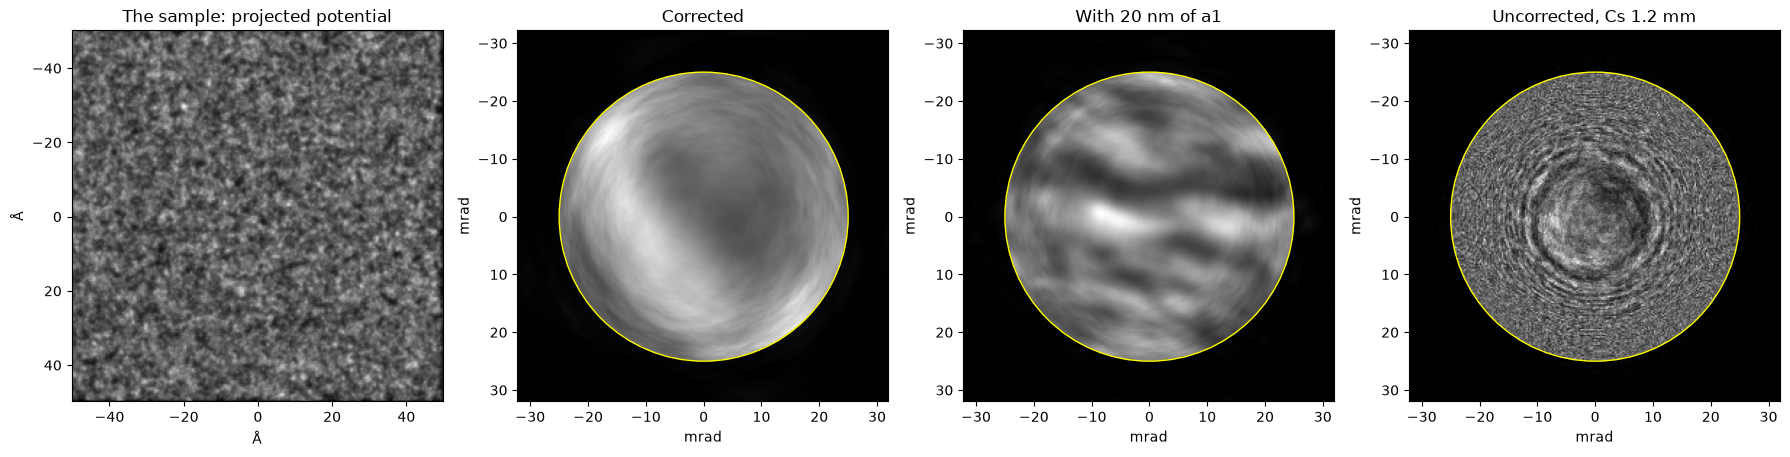

In [3]:
sample = corrected.random_potential(density=0.05, z=13, thickness=100, seed=1211)

astigmatic = Probe(kv=200, aperture=25, defocus=-5.14, cs=-0.00355, c5=3.829,
                   aberrations=CORRECTOR, size=100, sampling=256)
astigmatic.set_aberration('a1', 20.0, 30.0)       # 20 nm of two-fold astigmatism

uncorrected.scherzer()                             # its best defocus, explained in Step 4
uncorrected.aperture = 25.0                        # opened up to see the aberrations

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
corrected.show(sample, 'potential', ax=axes[0], title='The sample: projected potential')
for ax, (name, lens) in zip(axes[1:], (('Corrected', corrected),
                                       ('With 20 nm of a1', astigmatic),
                                       ('Uncorrected, Cs 1.2 mm', uncorrected))):
    lens.show(lens.ronchigram(sample), 'ronchigram', ax=ax, title=name)
plt.tight_layout()
plt.show()

The corrected Ronchigram is smooth over the whole 25 mrad aperture (yellow). Two-fold
astigmatism stretches the shadow in one direction. The uncorrected lens is flat only in its
center: beyond about 10 mrad, spherical aberration breaks the shadow into fine rings.

## Step 4: The STEM probe

The probe in the sample plane is the Fourier transform of the aperture times the phase factor
$e^{-i\chi}$. Its intensity sets the resolution of STEM images. `probe()` returns it normalized
to a total of 1, and `diameter()` gives the diameter of the circle holding a given share of it.

`diameter()` counts whole pixels, so the probe needs a map with pixels much smaller than itself:
25.6 Å with 512 pixels gives 0.05 Å.

For an uncorrected lens, `scherzer()` sets the defocus and aperture that make the probe
smallest: $\Delta f = -\sqrt{C_s\lambda}$ and $k_{max} = (4/C_s\lambda^3)^{1/4}$. For a corrected
lens, `haider()` sets the small negative $C_s$ and the defocus that balance $C_5$ at a given
aperture (Haider et al., 2000).

Scherzer: defocus -54.9 nm, aperture 9.56 mrad
Haider at 25 mrad: Cs -2.20 µm, defocus 0.22 nm


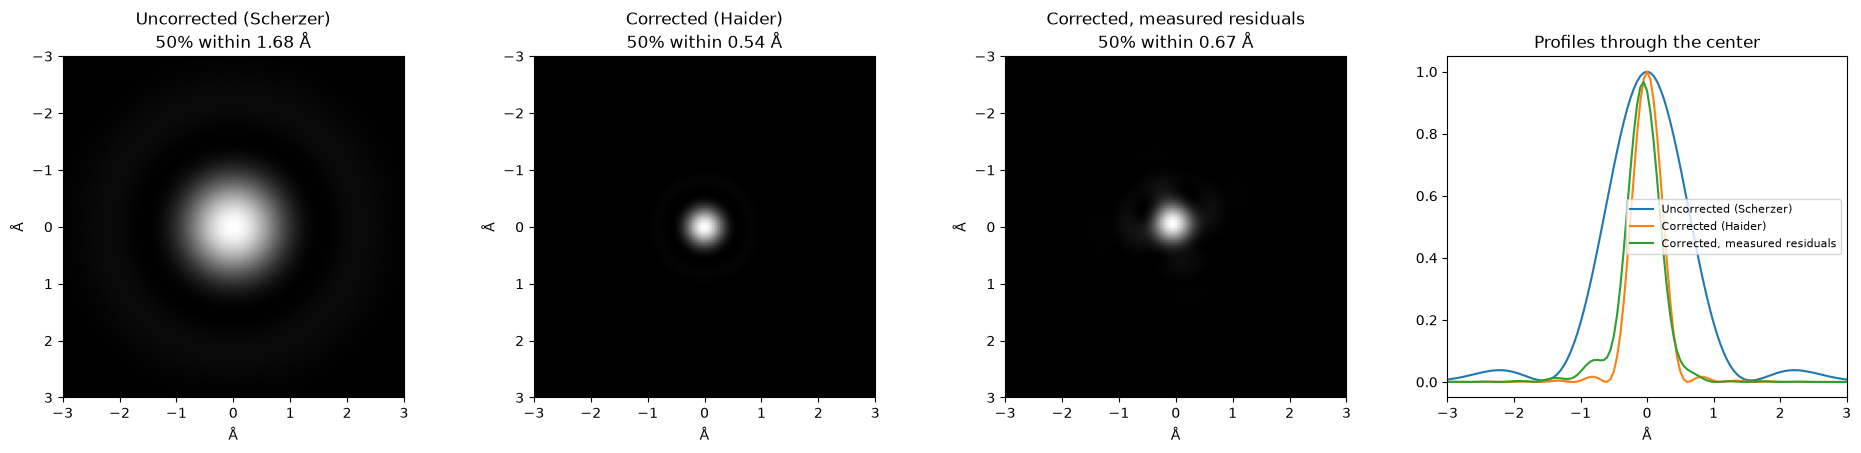

The diffraction limit of a 25 mrad aperture (Airy disk), 50% diameter: 0.52 Å


In [4]:
fine = {'size': 25.6, 'sampling': 512}
stem_uncorrected = Probe(kv=200, cs=1.2, **fine)
settings = stem_uncorrected.scherzer()
print(f"Scherzer: defocus {settings['defocus']:.1f} nm, aperture {settings['aperture']:.2f} mrad")

stem_corrected = Probe(kv=200, aperture=25, c5=3.829, **fine)
settings = stem_corrected.haider(optimum_aperture=False)
print(f"Haider at 25 mrad: Cs {settings['cs'] * 1000:.2f} µm, defocus {settings['defocus']:.2f} nm")
stem_residual = Probe(kv=200, aperture=25, c5=3.829, aberrations=CORRECTOR, **fine)
stem_residual.haider(optimum_aperture=False)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))
for ax, (name, lens) in zip(axes, (('Uncorrected (Scherzer)', stem_uncorrected),
                                   ('Corrected (Haider)', stem_corrected),
                                   ('Corrected, measured residuals', stem_residual))):
    intensity = lens.probe()
    d50 = lens.diameter(50, intensity)
    lens.show(intensity, 'probe', ax=ax, title=f'{name}\n50% within {d50:.2f} Å')
    ax.set_xlim(-3, 3)
    ax.set_ylim(3, -3)
    n = lens.sampling
    x = (np.arange(n) - n // 2) * lens.size / n
    axes[3].plot(x, intensity[n // 2] / intensity.max(), label=name)
axes[3].set_xlim(-3, 3)
axes[3].set_xlabel('Å')
axes[3].set_title('Profiles through the center')
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

wavelength = stem_corrected.wavelength
print(f'The diffraction limit of a 25 mrad aperture (Airy disk), 50% diameter: '
      f'{2 * 0.2572 * wavelength / 0.025:.2f} Å')

The corrector shrinks the probe threefold: its 25 mrad aperture, against 9.6 mrad for the
uncorrected lens, would be useless without it, because $C_s$ would blur the wider cone. At the
Haider settings the probe is within a few percent of the aperture's diffraction limit. The
residual aberrations a real corrector leaves enlarge it again and spread a tail around it: that's
why they're measured and tuned out.

How small the probe gets depends on the defocus. Here is the uncorrected probe's size across a
range of defocus:

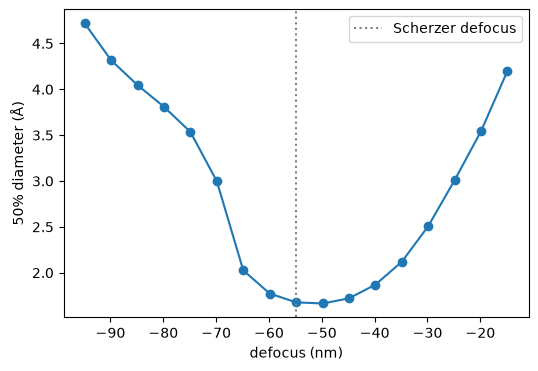

In [5]:
scherzer = stem_uncorrected.defocus
defocus = np.linspace(scherzer - 40, scherzer + 40, 17)
sizes = []
for df in defocus:
    stem_uncorrected.defocus = df
    sizes.append(stem_uncorrected.diameter(50))
stem_uncorrected.defocus = scherzer

plt.figure(figsize=(6, 4))
plt.plot(defocus, sizes, 'o-')
plt.axvline(scherzer, color='gray', linestyle=':', label='Scherzer defocus')
plt.xlabel('defocus (nm)')
plt.ylabel('50% diameter (Å)')
plt.legend()
plt.show()

## Step 5: The contrast transfer function

In a TEM, the lens is the objective lens, and it images the wave leaving the sample. For a thin
sample, the image shows each spatial frequency $k$ of the sample's potential multiplied by the
**contrast transfer function**, $\sin\chi(k)$. Where it's near $\pm 1$, those details show with
full contrast; where it crosses 0, they vanish; and its sign decides whether atoms look dark or
bright.

Two **coherence envelopes** damp it at high frequencies:

- the **temporal** one, from the chromatic aberration $C_c$ and the energy spread $\Delta E$,
  which spread the focus by $\Delta = C_c\,\Delta E/E$ (with a relativistic correction):
  $E_t(k) = \exp[-\tfrac12(\pi\lambda\Delta k^2)^2]$;
- the **spatial** one, from the illumination's semi-angle $q_0$:
  $E_s(k) = \exp[-(q_0/\lambda)^2\,(d\chi/dk)^2/(4\ln 2)]$.

At the Scherzer defocus for phase contrast, $\Delta f = -\sqrt{1.5\,C_s\lambda}$, the CTF keeps one
sign over the widest band of low frequencies; its first zero is the **point resolution**.

Scherzer defocus -67.2 nm, first zero near 0.42 1/Å (point resolution about 2.37 Å)


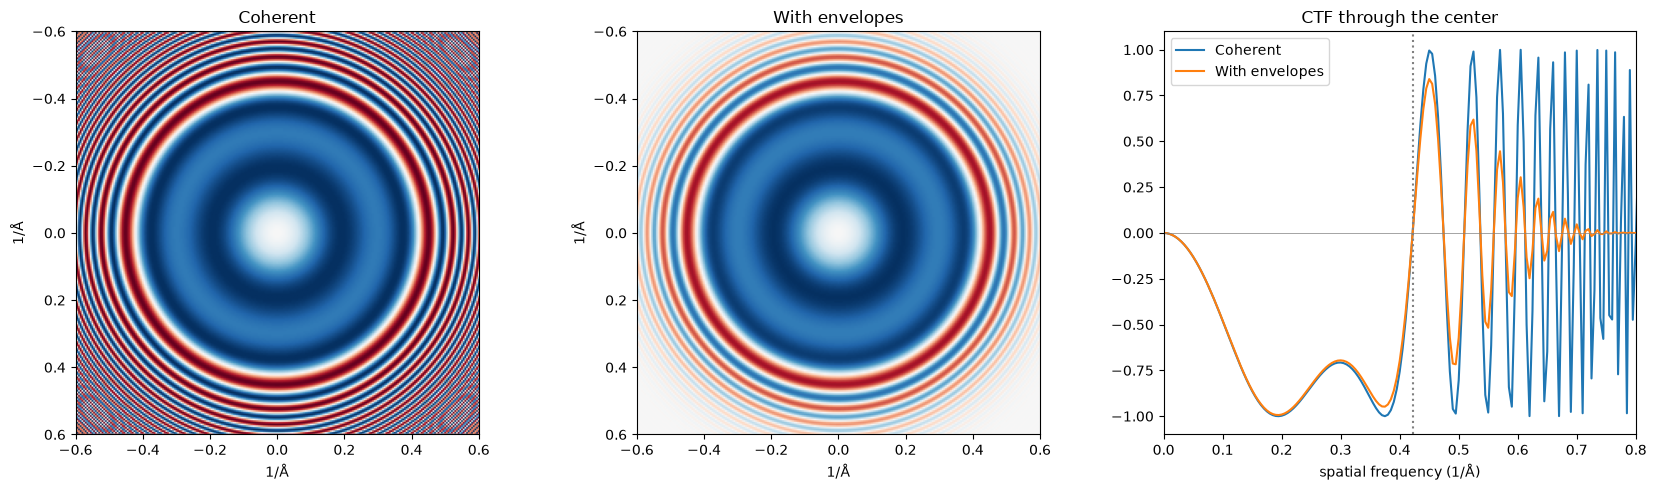

In [6]:
ctf_map = {'size': 200, 'sampling': 1024}     # 0.005 1/Å pixels, for the fast oscillations
coherent = Probe(kv=200, cs=1.2, semi_angle=0.0, **ctf_map)
coherent.scherzer(mode=2)
damped = Probe(kv=200, cs=1.2, cc=1.5, energy_spread=0.7, semi_angle=0.2, **ctf_map)
damped.scherzer(mode=2)
print(f'Scherzer defocus {damped.defocus:.1f} nm, first zero near {damped.kmax:.2f} 1/Å '
      f'(point resolution about {1 / damped.kmax:.2f} Å)')

def profile(lens, ctf):
    n = lens.sampling
    return np.arange(n // 2) / lens.size, ctf[n // 2, n // 2:]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, lens) in zip(axes, (('Coherent', coherent), ('With envelopes', damped))):
    lens.show(lens.ctf(), 'ctf', ax=ax, aperture=False, title=name)
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(0.6, -0.6)
for name, lens in (('Coherent', coherent), ('With envelopes', damped)):
    k, line = profile(lens, lens.ctf())
    axes[2].plot(k, line, label=name)
axes[2].axhline(0, color='gray', linewidth=0.5)
axes[2].axvline(damped.kmax, color='gray', linestyle=':')
axes[2].set_xlim(0, 0.8)
axes[2].set_xlabel('spatial frequency (1/Å)')
axes[2].set_title('CTF through the center')
axes[2].legend()
plt.tight_layout()
plt.show()

A corrector changes the picture. With a small negative $C_s$ and a little overfocus, the CTF
keeps one sign out to much higher frequencies, until the envelopes stop it:

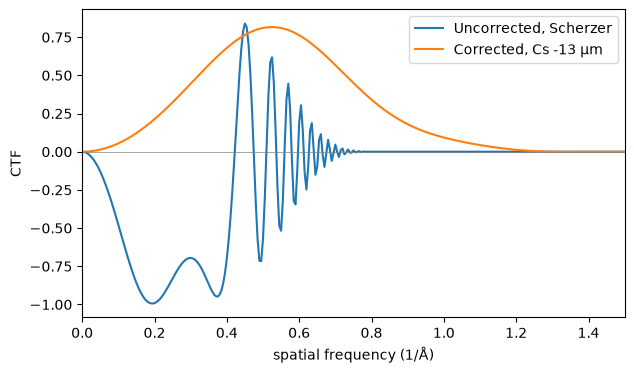

In [7]:
corrected_tem = Probe(kv=200, cs=-0.013, defocus=7.0, cc=1.5, energy_spread=0.7,
                      semi_angle=0.2, **ctf_map)
plt.figure(figsize=(7, 4))
for name, lens in (('Uncorrected, Scherzer', damped), ('Corrected, Cs -13 µm', corrected_tem)):
    k, line = profile(lens, lens.ctf())
    plt.plot(k, line, label=name)
plt.axhline(0, color='gray', linewidth=0.5)
plt.xlim(0, 1.5)
plt.xlabel('spatial frequency (1/Å)')
plt.ylabel('CTF')
plt.legend()
plt.show()

## Step 6: HREM images

A thin sample changes only the phase of the wave passing through it. Its **exit wave** is
$\psi(\mathbf r) = e^{i\sigma V(\mathbf r)}$, with the sample's projected potential $V$ and the
interaction constant $\sigma$, which depends on the high voltage. `exit_wave()` computes it, and
`hrem()` passes it through the objective lens: the aperture, the phase factor and the
envelopes. A multislice program's exit wave of a crystal works too.

Here is 50 Å of amorphous carbon, imaged at the Scherzer defocus and 40 nm further underfocus,
with a 20 mrad objective aperture:

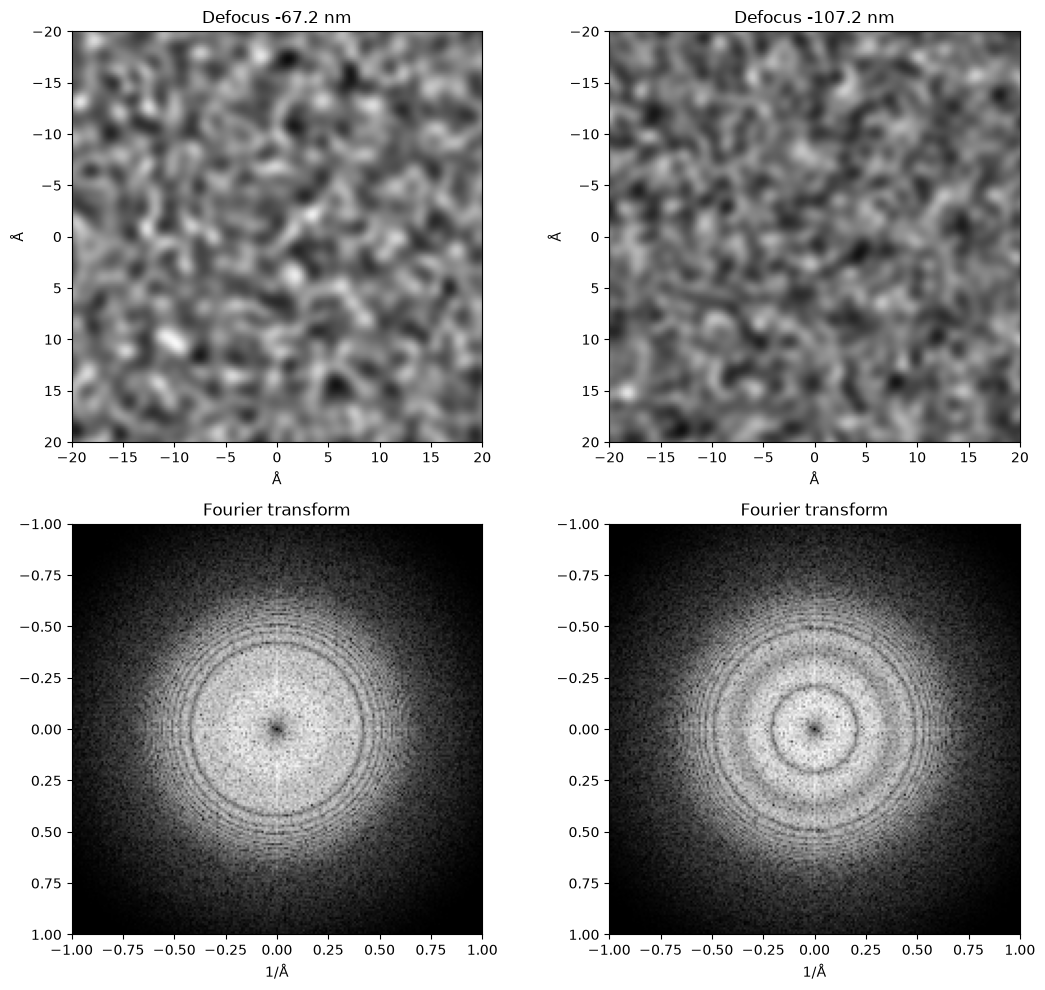

In [8]:
tem = Probe(kv=200, cs=1.2, cc=1.5, energy_spread=0.7, semi_angle=0.2, size=100, sampling=512)
tem.scherzer(mode=2)
tem.aperture = 20.0
scherzer = tem.defocus

carbon = tem.random_potential(density=0.1, z=6, thickness=50, seed=7)
wave = tem.exit_wave(carbon)

def spectrum(image):
    return np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(image - image.mean()))))

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for k, df in enumerate((scherzer, scherzer - 40)):
    tem.defocus = df
    image = tem.hrem(wave)
    tem.show(image, 'hrem', ax=axes[0, k], title=f'Defocus {df:.1f} nm')
    axes[0, k].set_xlim(-20, 20)
    axes[0, k].set_ylim(20, -20)
    axes[1, k].imshow(spectrum(image), cmap='gray', extent=tem.extent('ctf'))
    axes[1, k].set_xlim(-1, 1)
    axes[1, k].set_ylim(1, -1)
    axes[1, k].set_xlabel('1/Å')
    axes[1, k].set_title('Fourier transform')
tem.defocus = scherzer
plt.tight_layout()
plt.show()

The images look like noise, as an amorphous sample should, but their Fourier transforms show
**Thon rings**: the CTF's zeros, where the image has no contrast. More underfocus brings the rings
closer together. Microscopists measure defocus, $C_s$ and astigmatism from them.

For a weak sample the relation is exact: the image's spectrum is the potential's spectrum times
$\mathrm{CTF}^2$. Averaged around rings, the two match:

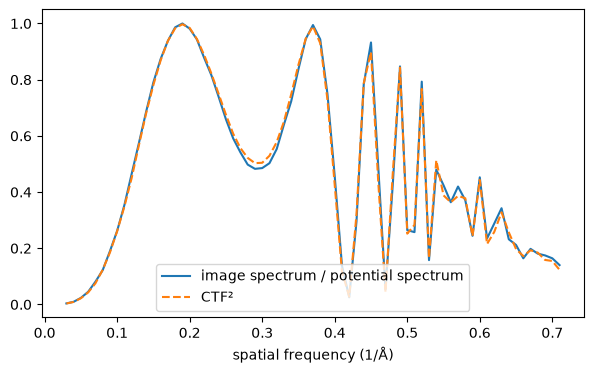

In [9]:
thin = tem.random_potential(density=0.1, z=6, thickness=10, seed=3)     # a weaker sample
tem_nocc = Probe(kv=200, cs=1.2, size=100, sampling=512)
tem_nocc.scherzer(mode=2)
tem_nocc.aperture = 20.0
image = tem_nocc.hrem(tem_nocc.exit_wave(thin))

n = tem_nocc.sampling
yy, xx = np.indices(image.shape)
ring = np.hypot(xx - n // 2, yy - n // 2).astype(int)
spec = np.abs(np.fft.fftshift(np.fft.fft2(image - image.mean()))) ** 2
vspec = np.abs(np.fft.fftshift(np.fft.fft2(thin - thin.mean()))) ** 2
ctf2 = tem_nocc.ctf() ** 2
inside = (ring > 2) & (ring < tem_nocc.kmax * tem_nocc.size * 0.9)
count = np.bincount(ring[inside])
keep = count > 0
ratio = (np.bincount(ring[inside], spec[inside])[keep] /
         np.bincount(ring[inside], vspec[inside])[keep])
k = np.arange(count.size)[keep] / tem_nocc.size

plt.figure(figsize=(7, 4))
plt.plot(k, ratio / ratio.max(), label='image spectrum / potential spectrum')
plt.plot(k, (np.bincount(ring[inside], ctf2[inside])[keep] / count[keep]), '--', label='CTF²')
plt.xlabel('spatial frequency (1/Å)')
plt.legend()
plt.show()

## Try it yourself

1. **Find the sweet spot.** In Step 3, change the corrected lens's defocus by ±10 nm. How does
   the flat area of the Ronchigram change? Then try 50 nm of axial coma, `set_aberration('b2',
   50, 0)`.
2. **Aperture size.** In Step 4, compute the uncorrected probe's 50% diameter with apertures from
   6 to 14 mrad. Why is there an optimum, and where is it?
3. **Chromatic aberration.** Give the corrected STEM lens `cc=1.5` and `energy_spread=0.6`. Which
   changes more, the 50% or the 80% diameter?
4. **One residual at a time.** Which of the measured residual aberrations enlarges the corrected
   probe most? Set them one by one with `set_aberration`.
5. **Point resolution.** In Step 5, how does the first zero of the CTF move from 200 kV to
   300 kV? Compare with $1/k_{max}$ from `scherzer(mode=2)`.
6. **Measure astigmatism.** In Step 6, add 30 nm of `a1` and look at the Thon rings. What shape
   are they, and how do they turn with the angle?

## Next

- The [virtual detector notebook](adf.ipynb): bright and dark field images from a 4D-STEM scan,
  which a STEM probe like the one in Step 4 records.
- The reference for [`Probe`](https://emlab-solutions.github.io/pyemaps/api/probe.html).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 8, *Coherent Nanoprobes. STEM. Defects and Amorphous Materials*, for Steps 3 and 4.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3):

- chapter 2, *Electron Waves*, for the waves of Steps 2, 5 and 6;
- chapter 10, *Instrumentation and Experimental Techniques*, for the microscope's lenses and
  correctors.